# E-commerce customer analytics: a short walkthrough

**Question.** A UK online gift retailer (many of its customers are wholesalers) wants to know who its
valuable customers are, how many come back, and which customer groups to target.

**Data.** UCI Machine Learning Repository, *Online Retail II* (CC BY 4.0): every invoice line from
1 Dec 2009 to 9 Dec 2011.

This notebook reads the outputs of `python -I src/run_all.py` (cleaning in pandas, analysis in DuckDB SQL)
and re-computes a few of them from the cleaned data, so you can see that the saved results reproduce.

In [1]:
from pathlib import Path
import sys

import duckdb
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
RESULTS, IMAGES, SQL = ROOT / "results", ROOT / "images", ROOT / "sql"
SALES = ROOT / "data" / "processed" / "sales_clean.parquet"
sys.path.insert(0, str(ROOT / "src"))
import segments  # segment names, rules and actions (src/segments.py)

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)
kpi = pd.read_csv(RESULTS / "key_metrics.csv").set_index("metric")["value"]

## 1. Cleaning: what was removed and why

Each raw line is counted once, under the first rule that catches it. Cancellations are not thrown away:
they are kept for the cancellation-rate metric. Lines with no Customer ID stay in revenue totals but are
left out of the customer analysis.

In [2]:
quality = pd.read_csv(RESULTS / "data_quality.csv")
quality[["step", "rule", "rows_affected", "pct_of_raw_lines", "value_gbp"]]

,step,rule,rows_affected,pct_of_raw_lines,value_gbp
0,0,Raw transaction lines (both sheets),1067371,100.00,19287250.57
1,1,Exact duplicate: sheet 2 repeats the last days of sheet 1,22523,2.11,377488.45
2,2,Exact duplicate: line repeated within the same sheet,11812,1.11,54228.42
3,3,"Cancellation lines (Invoice starts with ""C"")",19104,1.79,-1462050.61
4,4,"Quantity <= 0 or price <= 0 (stock write-offs, zero-price lines, b...",6019,0.56,-158676.14
5,5,"Non-product stock codes (postage, carriage, manual, discounts, sam...",4670,0.44,833814.16
6,6,Sale lines voided within 24 h by the same customer (identical canc...,1331,0.12,393101.24
7,7,Clean product sales lines,1001912,93.87,19249345.05
8,8,...of which: no Customer ID,226760,21.24,2575195.57
9,9,Unit price more than 10x the product's median price (possible mis-...,758,0.07,16078.38


Rule 6 matters more than its line count suggests. The largest lines in the whole file were keyed in and
cancelled minutes later; left in, they would inflate two customers' spend and two products' revenue:

In [3]:
pd.read_csv(RESULTS / "voided_sales_lines.csv").head(3)

,invoice,invoice_date,customer_id,stock_code,description,quantity,price,value_gbp,cancel_invoice,cancel_stock_code,minutes_to_cancel
0,581483,2011-12-09 09:15:00,16446,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,C581484,23843,12
1,541431,2011-01-18 10:01:00,12346,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,C541433,23166,16
2,556444,2011-06-10 15:28:00,15098,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0,C556445,M,3


## 2. Re-check: monthly revenue straight from the cleaned lines (pandas)

The monthly table in `results/` was produced by SQL. Here the same numbers are rebuilt with pandas from the
cleaned parquet file, reading only the three columns needed.

In [4]:
lines = pd.read_parquet(SALES, columns=["invoice", "invoice_date", "revenue"])
by_month = (lines.assign(month=lines["invoice_date"].dt.to_period("M").dt.to_timestamp())
                 .groupby("month")
                 .agg(revenue_gbp=("revenue", "sum"), orders=("invoice", "nunique"))
                 .round(2))
monthly = pd.read_csv(RESULTS / "monthly_kpis.csv", parse_dates=["month"]).set_index("month")
assert (by_month["orders"] == monthly["orders"]).all()
assert (by_month["revenue_gbp"] - monthly["revenue_gbp"]).abs().max() < 0.01
print(f"pandas and SQL agree for all {len(by_month)} months")
monthly[["revenue_gbp", "orders", "active_customers", "new_customers", "avg_order_value_gbp",
         "cancellation_rate_pct", "is_partial_month"]].tail(6)

pandas and SQL agree for all 25 months


,revenue_gbp,orders,active_customers,new_customers,avg_order_value_gbp,cancellation_rate_pct,is_partial_month
month,,,,,,,
2011-07-01,686582.35,1449,945,101,473.83,1.45,False
2011-08-01,719443.55,1338,933,107,537.70,2.55,False
2011-09-01,1023654.61,1815,1258,188,564.00,1.22,False
2011-10-01,1089826.43,1993,1359,222,546.83,2.59,False
2011-11-01,1441880.43,2741,1658,191,526.04,1.05,False
2011-12-01,445325.76,812,611,28,548.43,1.14,True


Jan-Nov 2011 vs Jan-Nov 2010 revenue: 1.84%
Sep-Nov share of the last 12 full months: 37.55%


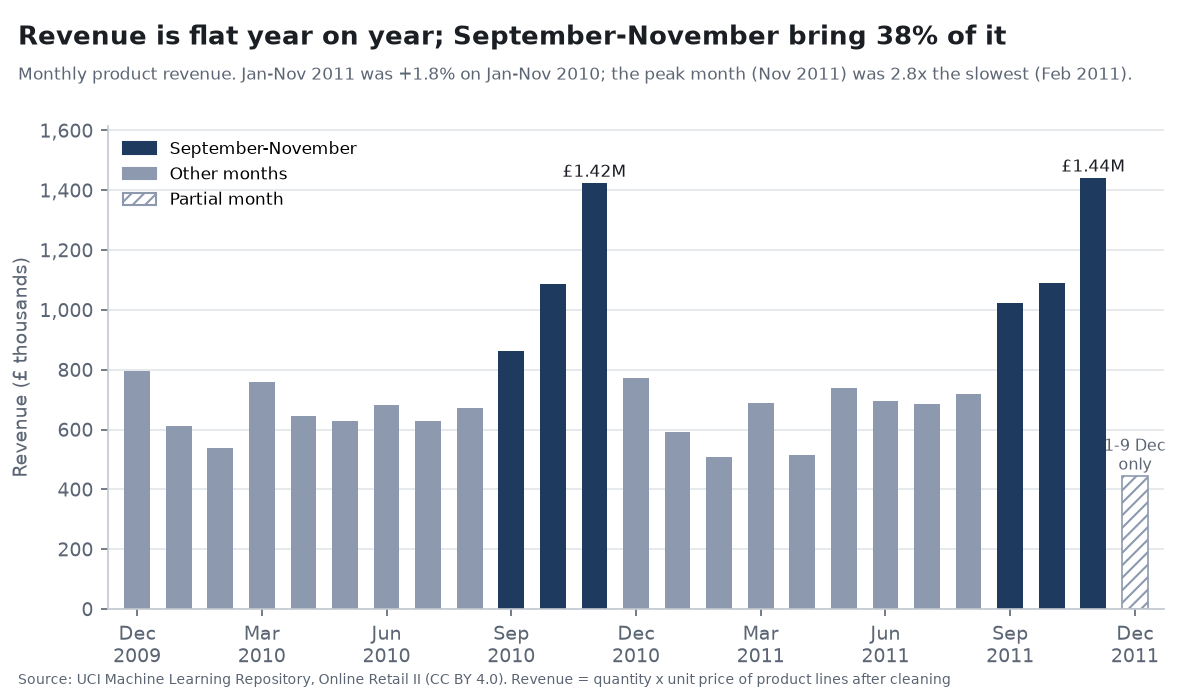

In [5]:
print(f"Jan-Nov 2011 vs Jan-Nov 2010 revenue: {kpi['revenue_growth_jan_nov_pct']}%")
print(f"Sep-Nov share of the last 12 full months: {kpi['sep_nov_share_of_12_months_pct']}%")
display(Image(filename=str(IMAGES / "monthly_revenue.png")))

## 3. Do customers come back?

Customers are grouped by the month of their first order (the *cohort*); the heatmap shows the share of each
cohort ordering in later months. December 2009 is marked because the data starts that month, so its "new"
customers include established ones (its month-1 rate is far above the others). The pooled curve leaves it out.

Pooled retention, months 1-12 after the first order:
months_since_first
1     20.89
2     21.53
3     21.12
4     19.36
5     18.51
6     18.48
7     18.63
8     16.37
9     15.00
10    13.40
11    13.98
12    18.42
December 2009 cohort, month 1: 34.91%


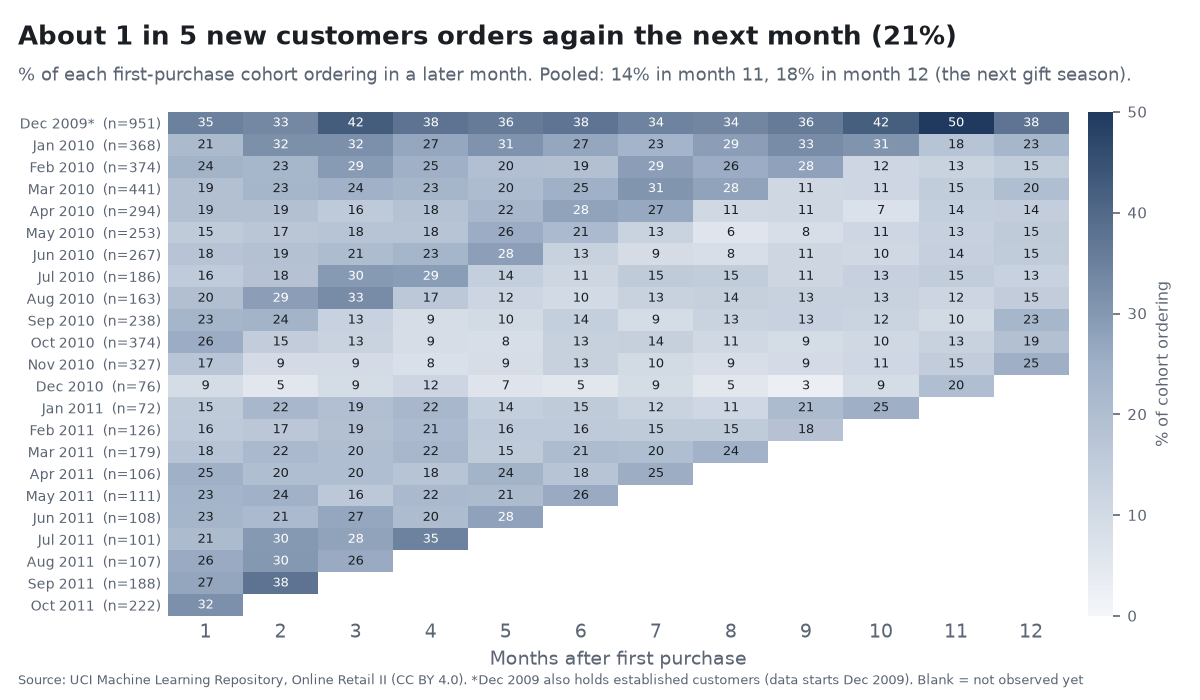

In [6]:
curve = pd.read_csv(RESULTS / "retention_curve.csv")
print("Pooled retention, months 1-12 after the first order:")
print(curve.set_index("months_since_first")["retention_pct"].head(12).to_string())
print(f"December 2009 cohort, month 1: {kpi['dec2009_cohort_month_1_pct']}%")
display(Image(filename=str(IMAGES / "cohort_retention_heatmap.png")))

Monthly retention looks low because many customers are shops that reorder every few months. Following
each new customer for a full year gives the fuller picture:

                           returned_customers  pct_returned
days_since_first_purchase                                  
30                                        532         15.97
60                                       1023         30.71
90                                       1351         40.56
180                                      1903         57.13
365                                      2323         69.74
Half of those who came back within a year did so within 72 days.


,first_purchase_month,new_customers,avg_revenue_365d_gbp,median_revenue_365d_gbp,avg_first_day_revenue_gbp,pct_of_365d_revenue_after_first_day,pct_bought_again_within_365d
12,All eligible,3331,1480.96,711.81,424.28,71.35,69.74


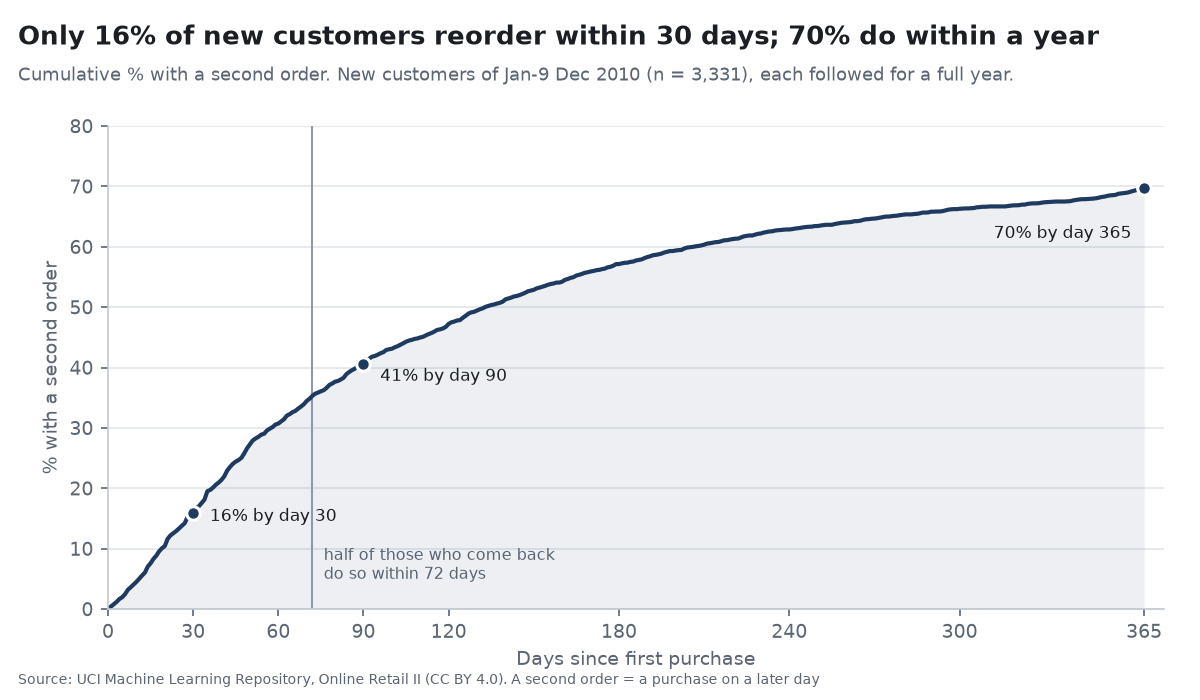

In [7]:
timing = pd.read_csv(RESULTS / "repeat_purchase_timing.csv").set_index("days_since_first_purchase")
print(timing.loc[[30, 60, 90, 180, 365], ["returned_customers", "pct_returned"]].to_string())
print(f"Half of those who came back within a year did so within "
      f"{int(kpi['median_days_to_second_order_returners'])} days.")
first_year = pd.read_csv(RESULTS / "first_year_value.csv")
display(first_year.tail(1))
display(Image(filename=str(IMAGES / "days_to_second_order.png")))

## 4. RFM segments: the SQL, run live

`sql/04_rfm_customers.sql` scores every identified customer 1-5 on recency, frequency and monetary value with
`NTILE(5)` window functions (tied values share a score), then maps the scores to eight segments.
Running it again here returns exactly the saved result.

In [8]:
con = duckdb.connect()
con.execute(f"CREATE VIEW sales AS SELECT * FROM read_parquet('{SALES.as_posix()}')")
rfm = con.execute((SQL / "04_rfm_customers.sql").read_text()).df()
saved = pd.read_csv(RESULTS / "rfm_customers.csv")
check = rfm.merge(saved, on="customer_id", suffixes=("", "_saved"))
assert len(check) == len(saved) == len(rfm)
for col in ["r_score", "f_score", "m_score", "segment"]:
    assert (check[col] == check[col + "_saved"]).all(), col
print(f"re-run matches results/rfm_customers.csv for all {len(rfm):,} customers")
segments.verify(rfm)          # the same rules re-implemented in Python
con.close()

summary = pd.read_csv(RESULTS / "rfm_segments.csv")
summary[["segment", "rule", "customers", "pct_of_customers", "pct_of_revenue",
         "median_revenue_per_customer_gbp", "median_days_since_last_order"]]

re-run matches results/rfm_customers.csv for all 5,851 customers
  segments: SQL and Python rules agree for all 5,851 customers


,segment,rule,customers,pct_of_customers,pct_of_revenue,median_revenue_per_customer_gbp,median_days_since_last_order
0,Champions,R >= 4 and F >= 4 and M >= 4,1244,21.26,68.55,3960.88,16.0
1,Can't Lose,R <= 2 and F >= 4 and M >= 4,207,3.54,5.25,2303.09,321.0
2,At Risk,R <= 2 and F >= 3 (not Can't Lose),503,8.60,3.31,871.36,374.0
3,Loyal,R >= 3 and F >= 3 (not Champions),1330,22.73,15.69,1157.31,65.0
4,Potential Loyalists,R >= 4 and F = 2,270,4.61,1.16,547.07,23.0
5,New,R >= 4 and F = 1,236,4.03,0.47,237.75,30.0
6,Hibernating,R = 2 or 3 and F <= 2,1101,18.82,3.14,328.80,237.0
7,Lost,R = 1 and F <= 2,960,16.41,2.42,263.62,548.5


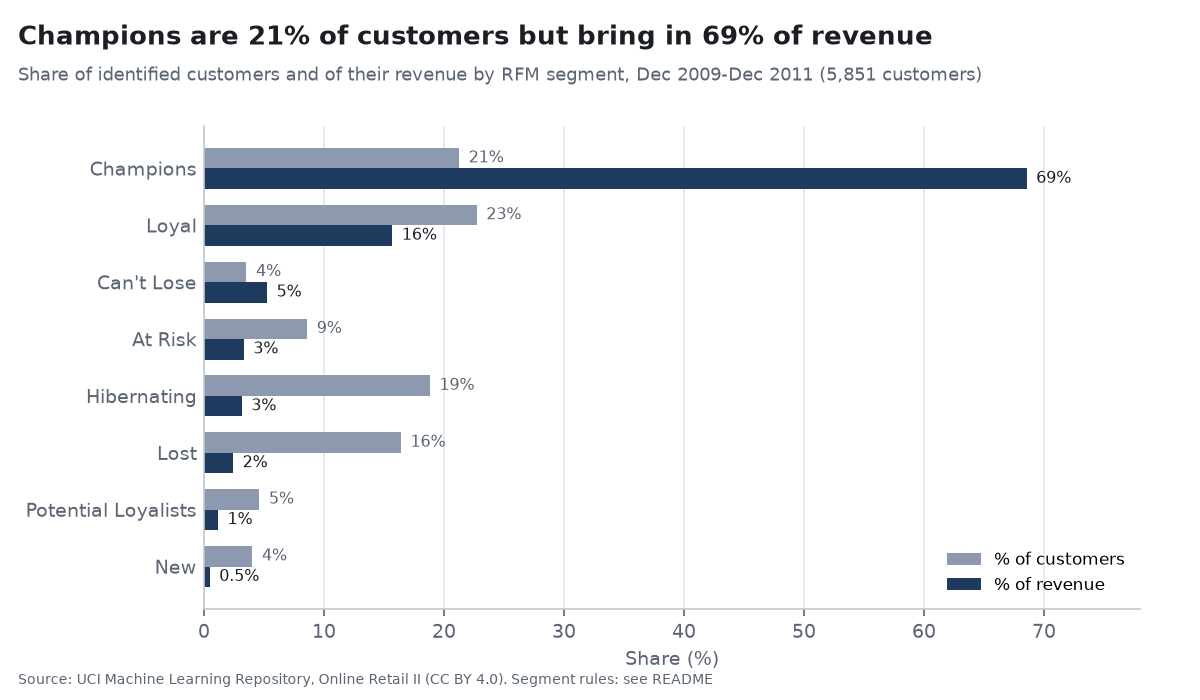

segment
Champions              Protect: account contact, early access to the autumn range; no bla...
Can't Lose             Personal win-back call or email before the next peak; ask why they...
At Risk                Win-back emails featuring products they bought before, with a time...
Loyal                        Cross-sell best-sellers they have not tried; reorder reminders.
Potential Loyalists           Push for the third order: reorder reminder and a bundle offer.
New                    Welcome series that asks for a second order within the first few w...
Hibernating                   Low-cost reactivation only in the seasonal (Sep-Nov) campaign.
Lost                                   Keep out of paid campaigns; cheap bulk email at most.


In [9]:
display(Image(filename=str(IMAGES / "segments_customers_vs_revenue.png")))
print(summary.set_index("segment")["action"].to_string())

## 5. Products and countries

,measure,products,pct_of_products,pct_of_revenue
0,top 1% of products,48,1.02,18.4182
1,top 5% of products,236,5.01,45.2697
2,top 10% of products,472,10.01,61.3720
3,top 20% of products,943,20.00,77.7293
4,top 50% of products,2358,50.01,95.3374
5,products needed for 50% of revenue,292,6.19,50.0000
6,products needed for 80% of revenue,1043,22.12,80.0000


,revenue_rank,stock_code,description,revenue_gbp,pct_of_revenue
0,1,22423,REGENCY CAKESTAND 3 TIER,328459.72,1.7063
1,2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,258797.53,1.3444
2,3,85099B,JUMBO BAG RED RETROSPOT,181334.55,0.9420
3,4,47566,PARTY BUNTING,148270.58,0.7703
4,5,84879,ASSORTED COLOUR BIRD ORNAMENT,128989.40,0.6701


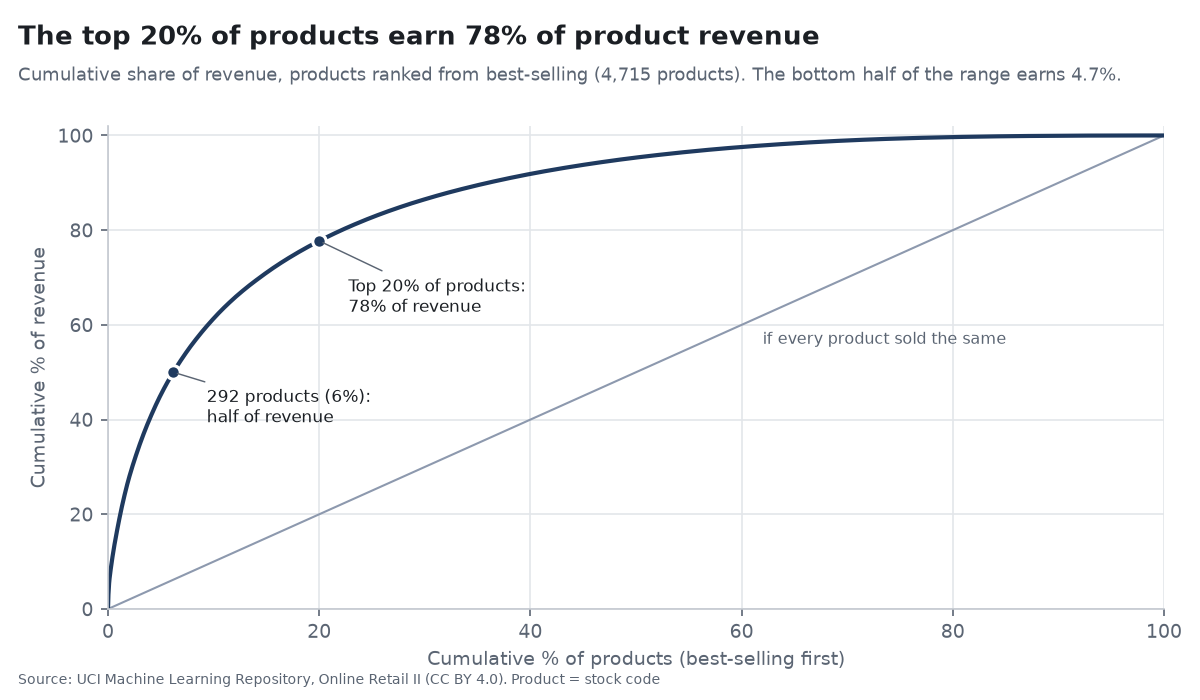

In [10]:
display(pd.read_csv(RESULTS / "pareto_summary.csv"))
display(pd.read_csv(RESULTS / "product_pareto.csv")[["revenue_rank", "stock_code", "description",
                                                       "revenue_gbp", "pct_of_revenue"]].head(5))
display(Image(filename=str(IMAGES / "product_pareto.png")))

,country,revenue_gbp,pct_of_revenue,pct_of_non_uk_revenue,customers
0,United Kingdom,16418827.60,85.30,NaN,5334
1,EIRE,615128.78,3.20,21.73,3
2,Netherlands,549773.41,2.86,19.42,22
3,Germany,383166.10,1.99,13.54,107
4,France,309845.99,1.61,10.95,93
5,Australia,167498.41,0.87,5.92,15


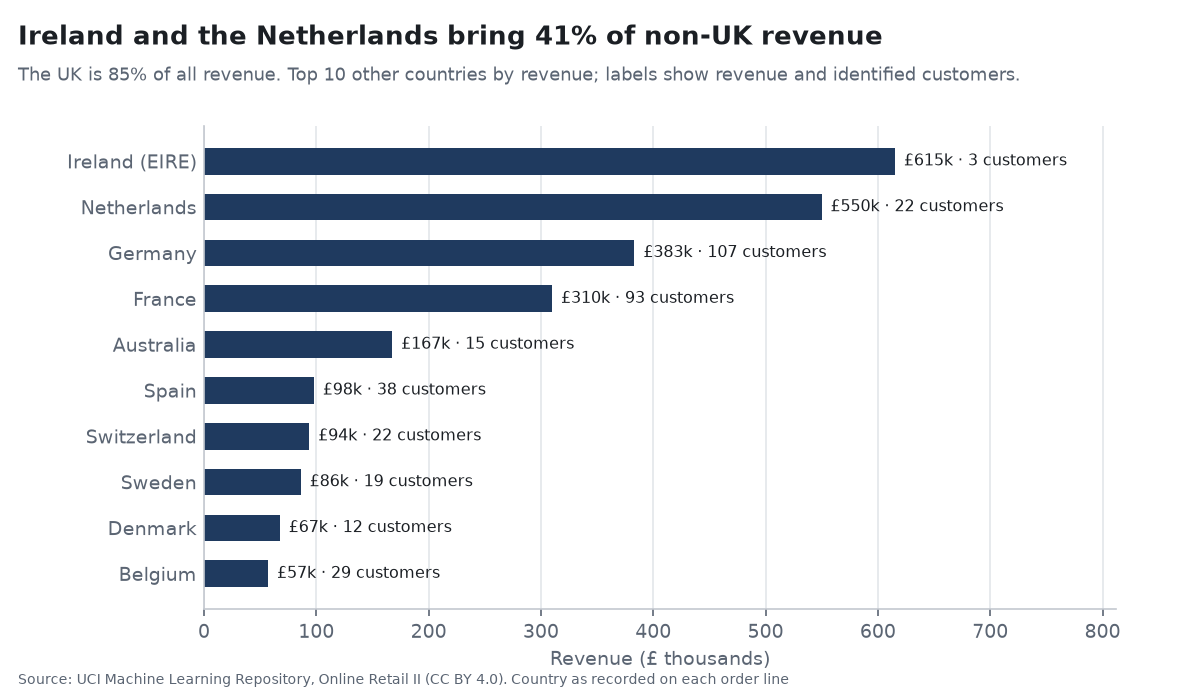

In [11]:
countries = pd.read_csv(RESULTS / "country_revenue.csv")
display(countries[["country", "revenue_gbp", "pct_of_revenue", "pct_of_non_uk_revenue", "customers"]].head(6))
display(Image(filename=str(IMAGES / "top_countries_ex_uk.png")))

## 6. What to act on

1. **Protect the Champions** - they carry most of the revenue; give them account contacts and early access
   to the autumn range before the September-November peak.
2. **Win back Can't Lose and At Risk customers** before the next peak, with a random hold-out group so the
   extra revenue can be measured rather than assumed.
3. **Ask for the second order early** - most of a new customer's first-year value comes after the first day,
   and most returners come back within a few months.
4. **Capture Customer IDs** on more orders - revenue without one cannot be used for retention or targeting.

The README has the numbers behind each point; `results/customer_analytics_report.xlsx` has the same results
as an Excel report with live formulas.